In [5]:
import numpy as np
import pandas as pd

df = pd.read_csv(
    "../dataset/Telco-Customer-Churn-Feature-Engineered.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (7021, 35)
   SeniorCitizen  Partner  Dependents  tenure  PhoneService  PaperlessBilling  \
0              0        1           0       1             0                 1   
1              0        0           0      34             1                 0   
2              0        0           0       2             1                 1   
3              0        0           0      45             0                 0   
4              0        0           0       2             1                 1   

   MonthlyCharges  TotalCharges  Churn  gender_Male  ...  StreamingMovies_Yes  \
0           29.85         29.85      0            0  ...                    0   
1           56.95       1889.50      0            1  ...                    0   
2           53.85        108.15      1            1  ...                    0   
3           42.30       1840.75      0            1  ...                    0   
4           70.70        151.65      1            0  

In [6]:
# Separate input features and target variable

X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Input features shape: (7021, 34)
Target variable shape: (7021,)

Target distribution:
Churn
0    5164
1    1857
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5616, 34)
X_test: (1405, 34)
y_train: (5616,)
y_test: (1405,)


In [8]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Churn
0    73.557692
1    26.442308
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.523132
1    26.476868
Name: proportion, dtype: float64


In [9]:
from sklearn.preprocessing import StandardScaler

# Select continuous numerical features
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "TotalServices"
]

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

# Use the same fitted scaler on testing data
X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

print("Training data after scaling:")
print(X_train_scaled[numerical_features].head())

print("\nTesting data after scaling:")
print(X_test_scaled[numerical_features].head())

Training data after scaling:
        tenure  MonthlyCharges  TotalCharges  TotalServices
2624 -1.241331        0.193165     -0.944714      -0.931930
2645 -0.711078        0.647355     -0.434062       0.364080
1416  1.409933        0.820380      1.794294       0.364080
5760 -1.118965        0.023467     -0.857170       0.364080
2420 -0.262403       -1.483847     -0.781865      -1.363933

Testing data after scaling:
        tenure  MonthlyCharges  TotalCharges  TotalServices
5615 -1.037387        0.331252     -0.793292      -0.499927
6112 -0.547923        1.031670     -0.225199       0.364080
2356 -1.282119       -0.630368     -0.986355      -0.931930
2196  0.145484        0.697266      0.313448       1.660089
832   1.532299        0.306296      1.288542       1.228086


In [10]:
print("Training feature means:")
print(X_train_scaled[numerical_features].mean())

print("\nTraining feature standard deviations:")
print(X_train_scaled[numerical_features].std(ddof=0))

Training feature means:
tenure            6.958663e-17
MonthlyCharges   -3.694417e-16
TotalCharges     -1.394896e-16
TotalServices     3.669113e-17
dtype: float64

Training feature standard deviations:
tenure            1.0
MonthlyCharges    1.0
TotalCharges      1.0
TotalServices     1.0
dtype: float64


In [11]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [12]:
logistic_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [13]:
# Predict churn class

y_pred = logistic_model.predict(X_test_scaled)

print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 predicted values:")
print(y_pred[:20])

First 20 actual values:
[0 1 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0]

First 20 predicted values:
[1 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0]


In [14]:
# Predict churn probabilities

y_probability = logistic_model.predict_proba(X_test_scaled)

print("First 10 prediction probabilities:")
print(y_probability[:10])

First 10 prediction probabilities:
[[0.21604316 0.78395684]
 [0.44751756 0.55248244]
 [0.69954553 0.30045447]
 [0.95553635 0.04446365]
 [0.98892048 0.01107952]
 [0.7131716  0.2868284 ]
 [0.83592716 0.16407284]
 [0.17401529 0.82598471]
 [0.98783651 0.01216349]
 [0.98763825 0.01236175]]


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

roc_auc = roc_auc_score(
    y_test,
    y_probability[:, 1]
)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

Logistic Regression Performance
--------------------------------
Accuracy : 0.802846975088968
Precision: 0.6727272727272727
Recall   : 0.49731182795698925
F1 Score : 0.5718701700154559
ROC-AUC  : 0.840649689285826


In [16]:
from sklearn.metrics import confusion_matrix, classification_report

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[943  90]
 [187 185]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1033
           1       0.67      0.50      0.57       372

    accuracy                           0.80      1405
   macro avg       0.75      0.71      0.72      1405
weighted avg       0.79      0.80      0.79      1405



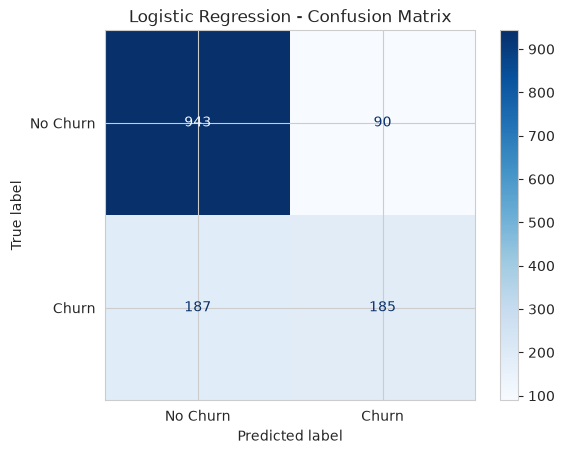

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [18]:
y_pred = logistic_model.predict(X_test_scaled)

In [19]:
y_probability = logistic_model.predict_proba(X_test_scaled)[:, 1]

y_pred = (y_probability >= 0.5).astype(int)

In [20]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get probability of churn
y_probability = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Test different thresholds
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:

    y_threshold_pred = (y_probability >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_threshold_pred),
        "Precision": precision_score(y_test, y_threshold_pred),
        "Recall": recall_score(y_test, y_threshold_pred),
        "F1 Score": f1_score(y_test, y_threshold_pred)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3))

   Threshold  Accuracy  Precision  Recall  F1 Score
0        0.3     0.759      0.533   0.742     0.620
1        0.4     0.782      0.584   0.616     0.599
2        0.5     0.803      0.673   0.497     0.572
3        0.6     0.788      0.701   0.347     0.464
4        0.7     0.769      0.753   0.188     0.301


In [21]:
from sklearn.metrics import confusion_matrix, classification_report

# Select threshold
best_threshold = 0.3

# Generate predictions
y_pred_03 = (y_probability >= best_threshold).astype(int)

# Confusion matrix
cm_03 = confusion_matrix(y_test, y_pred_03)

print("Confusion Matrix at Threshold 0.3:")
print(cm_03)

print("\nClassification Report at Threshold 0.3:")
print(classification_report(y_test, y_pred_03))

Confusion Matrix at Threshold 0.3:
[[791 242]
 [ 96 276]]

Classification Report at Threshold 0.3:
              precision    recall  f1-score   support

           0       0.89      0.77      0.82      1033
           1       0.53      0.74      0.62       372

    accuracy                           0.76      1405
   macro avg       0.71      0.75      0.72      1405
weighted avg       0.80      0.76      0.77      1405



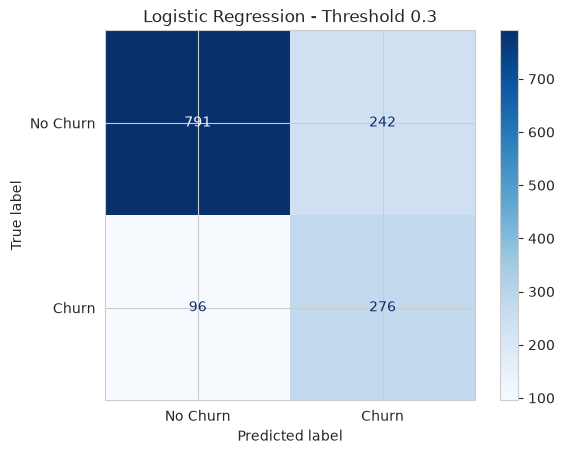

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_03,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Threshold 0.3")
plt.show()

In [23]:
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [24]:
decision_tree_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [25]:
# Display tree information
print("Tree Depth:", decision_tree_model.get_depth())

print("Number of Leaf Nodes:", decision_tree_model.get_n_leaves())

print("Number of Input Features:", decision_tree_model.n_features_in_)

Tree Depth: 27
Number of Leaf Nodes: 1138
Number of Input Features: 34


In [26]:
# Predict customer churn
y_pred_dt = decision_tree_model.predict(X_test)

print("First 20 Actual Values:")
print(y_test.head(20).values)

print("\nFirst 20 Predicted Values:")
print(y_pred_dt[:20])

First 20 Actual Values:
[0 1 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0]

First 20 Predicted Values:
[1 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0]


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

# Probability predictions
y_probability_dt = decision_tree_model.predict_proba(X_test)[:, 1]

roc_auc_dt = roc_auc_score(y_test, y_probability_dt)

print("Decision Tree Performance")
print("-------------------------")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1 Score :", f1_dt)
print("ROC-AUC  :", roc_auc_dt)

Decision Tree Performance
-------------------------
Accuracy : 0.7181494661921708
Precision: 0.46808510638297873
Recall   : 0.4731182795698925
F1 Score : 0.47058823529411764
ROC-AUC  : 0.6397537186813644


In [28]:
# Training predictions
y_train_pred_dt = decision_tree_model.predict(X_train)

# Training and testing accuracy
train_accuracy_dt = accuracy_score(y_train, y_train_pred_dt)
test_accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Training Accuracy:", train_accuracy_dt)
print("Testing Accuracy :", test_accuracy_dt)

Training Accuracy: 0.9976851851851852
Testing Accuracy : 0.7181494661921708


In [29]:
# Create an improved Decision Tree
decision_tree_model_v2 = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

# Train the model
decision_tree_model_v2.fit(X_train, y_train)

print("Improved Decision Tree trained successfully!")

Improved Decision Tree trained successfully!


In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predictions
y_pred_dt_v2 = decision_tree_model_v2.predict(X_test)

# Probabilities
y_probability_dt_v2 = decision_tree_model_v2.predict_proba(X_test)[:, 1]

# Metrics
print("Improved Decision Tree Performance")
print("----------------------------------")

print("Accuracy :",
      accuracy_score(y_test, y_pred_dt_v2))

print("Precision:",
      precision_score(y_test, y_pred_dt_v2))

print("Recall   :",
      recall_score(y_test, y_pred_dt_v2))

print("F1 Score :",
      f1_score(y_test, y_pred_dt_v2))

print("ROC-AUC  :",
      roc_auc_score(y_test, y_probability_dt_v2))

Improved Decision Tree Performance
----------------------------------
Accuracy : 0.7886120996441282
Precision: 0.6530612244897959
Recall   : 0.43010752688172044
F1 Score : 0.5186385737439222
ROC-AUC  : 0.8211532856592657


In [31]:
y_train_pred_dt_v2 = decision_tree_model_v2.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_dt_v2))

print("Testing Accuracy :",
      accuracy_score(y_test, y_pred_dt_v2))

print("Tree Depth:",
      decision_tree_model_v2.get_depth())

print("Leaf Nodes:",
      decision_tree_model_v2.get_n_leaves())

Training Accuracy: 0.8009259259259259
Testing Accuracy : 0.7886120996441282
Tree Depth: 5
Leaf Nodes: 30


In [32]:
import pandas as pd

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": decision_tree_model_v2.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
print(feature_importance.head(15))

Top 15 Important Features:
                                Feature  Importance
3                                tenure    0.438625
11          InternetService_Fiber optic    0.359144
7                          TotalCharges    0.047249
6                        MonthlyCharges    0.027648
25                    Contract_One year    0.025957
23  StreamingMovies_No internet service    0.023018
28       PaymentMethod_Electronic check    0.019176
13   OnlineSecurity_No internet service    0.018831
26                    Contract_Two year    0.018764
10                    MultipleLines_Yes    0.014276
4                          PhoneService    0.007312
0                         SeniorCitizen    0.000000
1                               Partner    0.000000
12                   InternetService_No    0.000000
9        MultipleLines_No phone service    0.000000


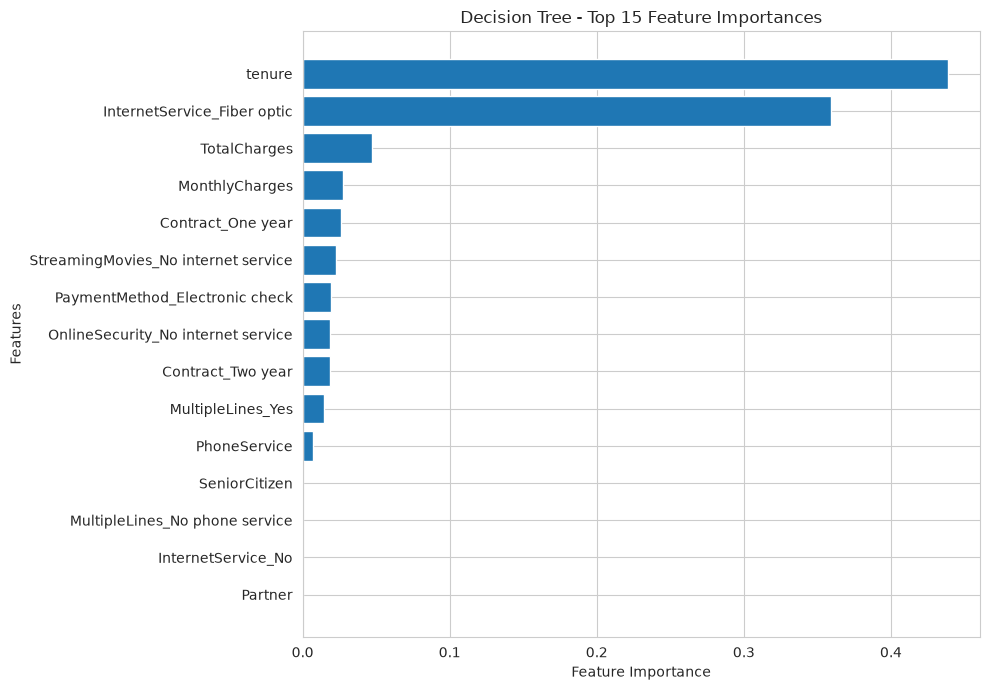

In [33]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Decision Tree - Top 15 Feature Importances")

plt.tight_layout()
plt.show()

In [34]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

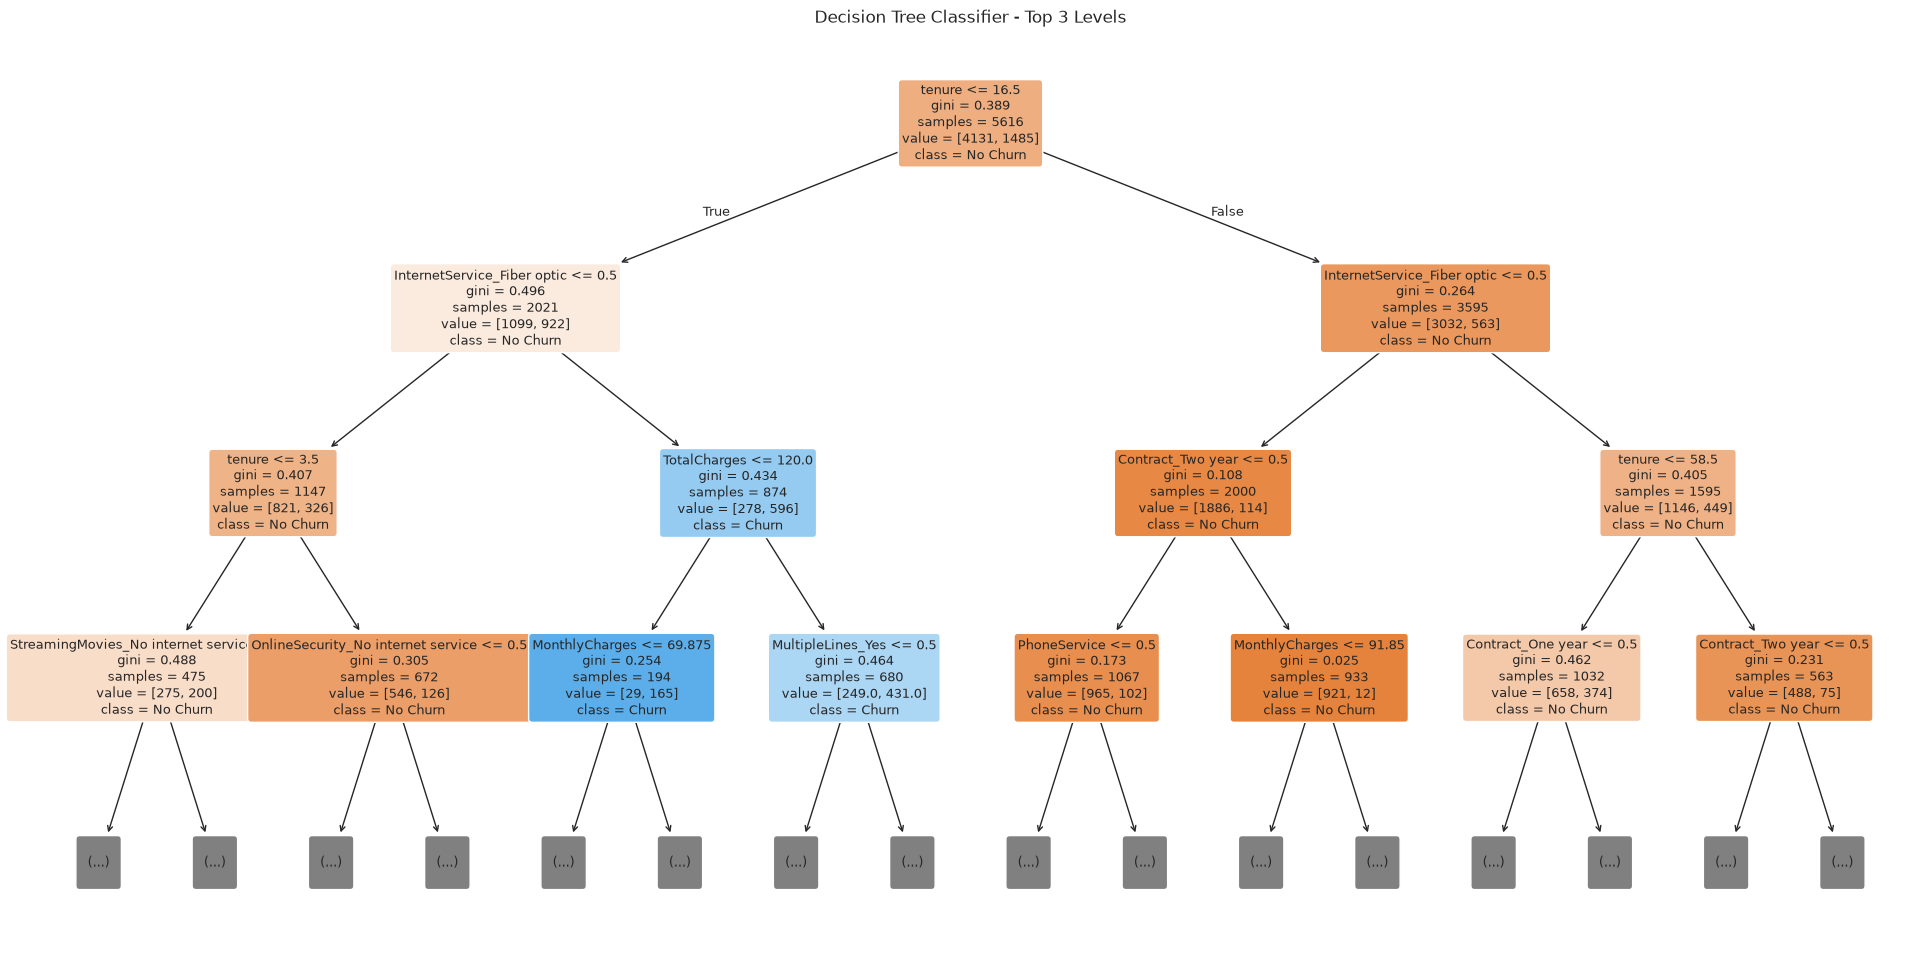

In [35]:
plt.figure(figsize=(24, 12))

plot_tree(
    decision_tree_model_v2,
    feature_names=X_train.columns,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Classifier - Top 3 Levels")
plt.show()


In [36]:
from sklearn.tree import export_text

tree_rules = export_text(
    decision_tree_model_v2,
    feature_names=list(X_train.columns),
    max_depth=3
)

print(tree_rules)

|--- tenure <= 16.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- tenure <= 3.50
|   |   |   |--- StreamingMovies_No internet service <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- StreamingMovies_No internet service >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- tenure >  3.50
|   |   |   |--- OnlineSecurity_No internet service <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- OnlineSecurity_No internet service >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- TotalCharges <= 120.00
|   |   |   |--- MonthlyCharges <= 69.88
|   |   |   |   |--- class: 1
|   |   |   |--- MonthlyCharges >  69.88
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- TotalCharges >  120.00
|   |   |   |--- MultipleLines_Yes <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- MultipleLines_Yes >  0.50
|   |   |   |   |--- trunca

In [37]:

tree_rules_full = export_text(
    decision_tree_model_v2,
    feature_names=list(X_train.columns)
)

print(tree_rules_full)

|--- tenure <= 16.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- tenure <= 3.50
|   |   |   |--- StreamingMovies_No internet service <= 0.50
|   |   |   |   |--- MonthlyCharges <= 56.40
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- MonthlyCharges >  56.40
|   |   |   |   |   |--- class: 0
|   |   |   |--- StreamingMovies_No internet service >  0.50
|   |   |   |   |--- TotalCharges <= 33.40
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- TotalCharges >  33.40
|   |   |   |   |   |--- class: 0
|   |   |--- tenure >  3.50
|   |   |   |--- OnlineSecurity_No internet service <= 0.50
|   |   |   |   |--- TotalCharges <= 310.90
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- TotalCharges >  310.90
|   |   |   |   |   |--- class: 0
|   |   |   |--- OnlineSecurity_No internet service >  0.50
|   |   |   |   |--- Contract_Two year <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Contract_Two year >  0.50
|   |   |   |   |   |--- class: 0
|   |-

In [38]:
from sklearn.ensemble import RandomForestClassifier

In [39]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    random_state=42,
    n_jobs=-1
)

In [40]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [41]:
print("Number of trees:",
      len(random_forest_model.estimators_))

print("Number of input features:",
      random_forest_model.n_features_in_)

print("Maximum depth of first tree:",
      random_forest_model.estimators_[0].get_depth())

print("Number of leaves in first tree:",
      random_forest_model.estimators_[0].get_n_leaves())

Number of trees: 100
Number of input features: 34
Maximum depth of first tree: 24
Number of leaves in first tree: 1219


In [42]:
# Predict customer churn
y_pred_rf = random_forest_model.predict(X_test)

# Predict churn probabilities
y_prob_rf = random_forest_model.predict_proba(X_test)

print("First 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred_rf[:20])

print("\nFirst 10 Prediction Probabilities:")
print(y_prob_rf[:10])

First 20 Actual Values:
[0 1 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0]

First 20 Predicted Values:
[1 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0]

First 10 Prediction Probabilities:
[[0.27  0.73 ]
 [0.61  0.39 ]
 [0.215 0.785]
 [0.83  0.17 ]
 [0.85  0.15 ]
 [0.72  0.28 ]
 [0.92  0.08 ]
 [0.09  0.91 ]
 [1.    0.   ]
 [0.99  0.01 ]]


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(y_test, y_pred_rf)

recall_rf = recall_score(y_test, y_pred_rf)

f1_rf = f1_score(y_test, y_pred_rf)

roc_auc_rf = roc_auc_score(y_test, y_prob_rf[:, 1])

# Display results
print("Random Forest Evaluation Metrics")
print("---------------------------------")

print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1 Score:  {f1_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Churn", "Churn"]
))

Random Forest Evaluation Metrics
---------------------------------
Accuracy:  0.7751
Precision: 0.6102
Recall:    0.4167
F1 Score:  0.4952
ROC-AUC:   0.8176

Confusion Matrix:
[[934  99]
 [217 155]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.81      0.90      0.86      1033
       Churn       0.61      0.42      0.50       372

    accuracy                           0.78      1405
   macro avg       0.71      0.66      0.68      1405
weighted avg       0.76      0.78      0.76      1405



In [44]:
# Extract feature importance
rf_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

# Sort features by importance
rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("Top 15 Random Forest Features:")
print(rf_feature_importance.head(15))

Top 15 Random Forest Features:
                           Feature  Importance
7                     TotalCharges    0.176470
6                   MonthlyCharges    0.152950
3                           tenure    0.141045
11     InternetService_Fiber optic    0.043767
30                   TotalServices    0.041937
28  PaymentMethod_Electronic check    0.036877
26               Contract_Two year    0.028849
8                      gender_Male    0.027068
5                 PaperlessBilling    0.026519
14              OnlineSecurity_Yes    0.022536
1                          Partner    0.022503
20                 TechSupport_Yes    0.021159
25               Contract_One year    0.021094
16                OnlineBackup_Yes    0.020752
0                    SeniorCitizen    0.020339


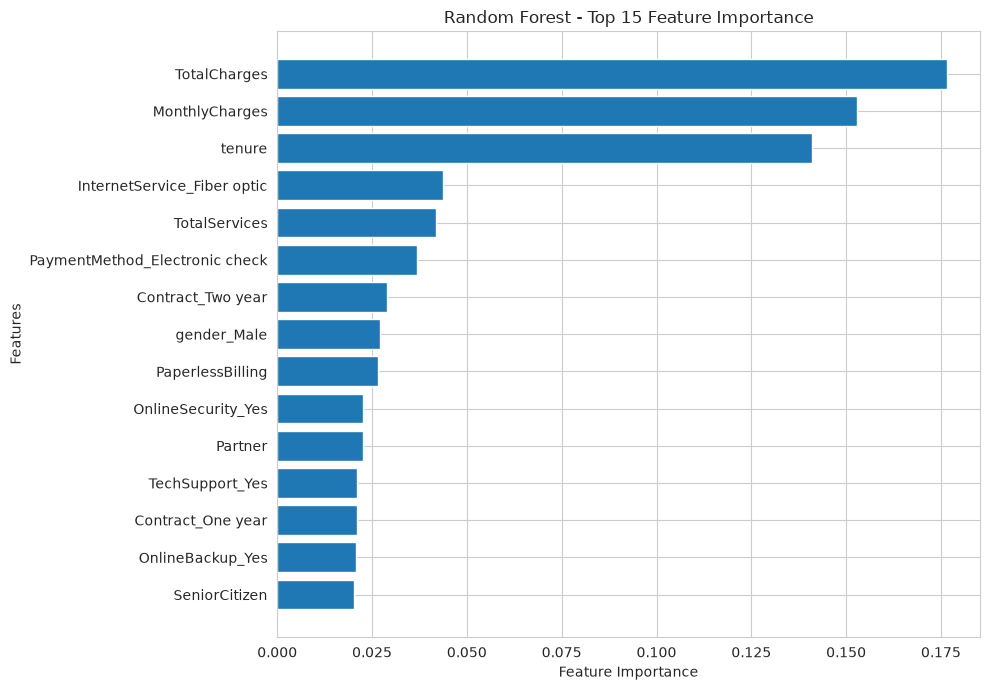

In [45]:
import matplotlib.pyplot as plt

top_features = rf_feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 15 Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [46]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [47]:
# Define hyperparameter search space

param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

In [48]:
rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_distributions,
    n_iter=20,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=2
)

In [49]:
rf_random_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END max_depth=15, max_features=log2, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time=   0.4s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   0.4s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=15, max_features=log2, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.5s[CV] END max_depth=15, max_features=log2, min_samples_leaf=1, min_samples_split=5, n_es

In [50]:
print("Best Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(rf_random_search.best_score_)

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None}

Best Cross-Validation F1 Score:
0.5783494101087181


In [51]:
best_rf_model = rf_random_search.best_estimator_

print("\nBest Random Forest Model:")
print(best_rf_model)


Best Random Forest Model:
RandomForestClassifier(max_features='log2', min_samples_leaf=2,
                       min_samples_split=10, n_estimators=200, n_jobs=-1,
                       random_state=42)


In [52]:
# Get the best tuned model
best_rf_model = rf_random_search.best_estimator_

# Predict customer churn
y_pred_rf_tuned = best_rf_model.predict(X_test)

# Predict churn probabilities
y_prob_rf_tuned = best_rf_model.predict_proba(X_test)

print("Tuned Random Forest predictions generated!")

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred_rf_tuned[:20])

Tuned Random Forest predictions generated!

First 20 Actual Values:
[0 1 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0]

First 20 Predicted Values:
[1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]


In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate metrics
accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)

precision_rf_tuned = precision_score(y_test, y_pred_rf_tuned)

recall_rf_tuned = recall_score(y_test, y_pred_rf_tuned)

f1_rf_tuned = f1_score(y_test, y_pred_rf_tuned)

roc_auc_rf_tuned = roc_auc_score(
    y_test,
    y_prob_rf_tuned[:, 1]
)

# Display results
print("Tuned Random Forest Evaluation Metrics")
print("--------------------------------------")

print(f"Accuracy:  {accuracy_rf_tuned:.4f}")
print(f"Precision: {precision_rf_tuned:.4f}")
print(f"Recall:    {recall_rf_tuned:.4f}")
print(f"F1 Score:  {f1_rf_tuned:.4f}")
print(f"ROC-AUC:   {roc_auc_rf_tuned:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf_tuned,
    target_names=["No Churn", "Churn"]
))

Tuned Random Forest Evaluation Metrics
--------------------------------------
Accuracy:  0.7936
Precision: 0.6507
Recall:    0.4758
F1 Score:  0.5497
ROC-AUC:   0.8335

Confusion Matrix:
[[938  95]
 [195 177]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.91      0.87      1033
       Churn       0.65      0.48      0.55       372

    accuracy                           0.79      1405
   macro avg       0.74      0.69      0.71      1405
weighted avg       0.78      0.79      0.78      1405



In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Improved Decision Tree predictions
y_pred_dt_v2 = decision_tree_model_v2.predict(X_test)

# Calculate metrics
accuracy_dt_v2 = accuracy_score(y_test, y_pred_dt_v2)
precision_dt_v2 = precision_score(y_test, y_pred_dt_v2)
recall_dt_v2 = recall_score(y_test, y_pred_dt_v2)
f1_dt_v2 = f1_score(y_test, y_pred_dt_v2)

roc_auc_dt_v2 = roc_auc_score(
    y_test,
    decision_tree_model_v2.predict_proba(X_test)[:, 1]
)

print("Improved Decision Tree Metrics")
print("--------------------------------")
print(f"Accuracy:  {accuracy_dt_v2:.4f}")
print(f"Precision: {precision_dt_v2:.4f}")
print(f"Recall:    {recall_dt_v2:.4f}")
print(f"F1 Score:  {f1_dt_v2:.4f}")
print(f"ROC-AUC:   {roc_auc_dt_v2:.4f}")

Improved Decision Tree Metrics
--------------------------------
Accuracy:  0.7886
Precision: 0.6531
Recall:    0.4301
F1 Score:  0.5186
ROC-AUC:   0.8212


In [56]:
y_pred_lr = logistic_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr)
recall = recall_score(y_test, y_pred_lr)
f1 = f1_score(y_test, y_pred_lr)

roc_auc = roc_auc_score(
    y_test,
    logistic_model.predict_proba(X_test_scaled)[:, 1]
)

In [57]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest (Baseline)",
        "Random Forest (Tuned)"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt_v2,
        accuracy_rf,
        accuracy_rf_tuned
    ],
    "Precision": [
        precision,
        precision_dt_v2,
        precision_rf,
        precision_rf_tuned
    ],
    "Recall": [
        recall,
        recall_dt_v2,
        recall_rf,
        recall_rf_tuned
    ],
    "F1 Score": [
        f1,
        f1_dt_v2,
        f1_rf,
        f1_rf_tuned
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_dt_v2,
        roc_auc_rf,
        roc_auc_rf_tuned
    ]
})

print(model_comparison.round(4))

                      Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0       Logistic Regression    0.8028     0.6727  0.4973    0.5719   0.8406
1             Decision Tree    0.7886     0.6531  0.4301    0.5186   0.8212
2  Random Forest (Baseline)    0.7751     0.6102  0.4167    0.4952   0.8176
3     Random Forest (Tuned)    0.7936     0.6507  0.4758    0.5497   0.8335


In [58]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Scale numerical columns inside each CV fold
preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), numerical_features)
    ],
    remainder="passthrough"
)

# Create a complete Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold churn probabilities
oof_probabilities = cross_val_predict(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold probabilities generated:", len(oof_probabilities))
print("\nFirst 10 probabilities:")
print(oof_probabilities[:10])

Out-of-fold probabilities generated: 5616

First 10 probabilities:
[0.53566153 0.41340175 0.22675766 0.38111363 0.12607715 0.43517397
 0.0092337  0.74674551 0.01923784 0.19071084]


In [59]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

thresholds = np.arange(0.20, 0.71, 0.05)

for threshold in thresholds:

    y_pred_threshold = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, y_pred_threshold),
        "Precision": precision_score(y_train, y_pred_threshold),
        "Recall": recall_score(y_train, y_pred_threshold),
        "F1 Score": f1_score(y_train, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

    Threshold  Accuracy  Precision  Recall  F1 Score
0        0.20    0.7082     0.4716  0.8606    0.6093
1        0.25    0.7415     0.5069  0.8182    0.6260
2        0.30    0.7609     0.5332  0.7677    0.6293
3        0.35    0.7819     0.5697  0.7158    0.6344
4        0.40    0.7943     0.6014  0.6593    0.6290
5        0.45    0.8011     0.6318  0.5939    0.6123
6        0.50    0.8068     0.6692  0.5327    0.5932
7        0.55    0.8018     0.6886  0.4572    0.5496
8        0.60    0.7977     0.7179  0.3872    0.5031
9        0.65    0.7911     0.7524  0.3131    0.4422
10       0.70    0.7815     0.7919  0.2357    0.3633


In [60]:
# Train Logistic Regression pipeline on training data
lr_pipeline.fit(X_train, y_train)

# Predict churn probabilities on test data
test_probabilities = lr_pipeline.predict_proba(X_test)[:, 1]

# Apply selected threshold
best_threshold = 0.35

y_pred_final = (
    test_probabilities >= best_threshold
).astype(int)

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Final Logistic Regression Results (Threshold = 0.35)")

print("Accuracy:",
      accuracy_score(y_test, y_pred_final))

print("Precision:",
      precision_score(y_test, y_pred_final))

print("Recall:",
      recall_score(y_test, y_pred_final))

print("F1 Score:",
      f1_score(y_test, y_pred_final))

print("ROC-AUC:",
      roc_auc_score(y_test, test_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

Final Logistic Regression Results (Threshold = 0.35)
Accuracy: 0.7715302491103203
Precision: 0.5562913907284768
Recall: 0.6774193548387096
F1 Score: 0.610909090909091
ROC-AUC: 0.840649689285826

Confusion Matrix:
[[832 201]
 [120 252]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.81      0.84      1033
           1       0.56      0.68      0.61       372

    accuracy                           0.77      1405
   macro avg       0.72      0.74      0.72      1405
weighted avg       0.79      0.77      0.78      1405



In [62]:
y_pred_default = (
    test_probabilities >= 0.50
).astype(int)

threshold_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],

    "Threshold 0.50": [
        accuracy_score(y_test, y_pred_default),
        precision_score(y_test, y_pred_default),
        recall_score(y_test, y_pred_default),
        f1_score(y_test, y_pred_default)
    ],

    "Threshold 0.35": [
        accuracy_score(y_test, y_pred_final),
        precision_score(y_test, y_pred_final),
        recall_score(y_test, y_pred_final),
        f1_score(y_test, y_pred_final)
    ]
})

print(threshold_comparison.round(4))

      Metric  Threshold 0.50  Threshold 0.35
0   Accuracy          0.8028          0.7715
1  Precision          0.6727          0.5563
2     Recall          0.4973          0.6774
3   F1 Score          0.5719          0.6109


In [63]:
from sklearn.metrics import confusion_matrix

cm_default = confusion_matrix(y_test, y_pred_default)
cm_optimized = confusion_matrix(y_test, y_pred_final)

print("Confusion Matrix - Threshold 0.50")
print(cm_default)

print("\nConfusion Matrix - Threshold 0.35")
print(cm_optimized)

Confusion Matrix - Threshold 0.50
[[943  90]
 [187 185]]

Confusion Matrix - Threshold 0.35
[[832 201]
 [120 252]]


In [64]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold probabilities
rf_oof_probabilities = cross_val_predict(
    best_rf_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Out-of-fold probabilities generated:",
      len(rf_oof_probabilities))

print("\nFirst 10 probabilities:")
print(rf_oof_probabilities[:10])

Out-of-fold probabilities generated: 5616

First 10 probabilities:
[0.49342423 0.42050538 0.24088397 0.20690775 0.07643487 0.27540669
 0.0055195  0.63214513 0.07075362 0.14232198]


In [65]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_threshold_results = []

thresholds = np.arange(0.20, 0.71, 0.05)

for threshold in thresholds:

    y_pred_threshold = (
        rf_oof_probabilities >= threshold
    ).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, y_pred_threshold),
        "Precision": precision_score(y_train, y_pred_threshold),
        "Recall": recall_score(y_train, y_pred_threshold),
        "F1 Score": f1_score(y_train, y_pred_threshold)
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print(rf_threshold_df.round(4))

    Threshold  Accuracy  Precision  Recall  F1 Score
0        0.20    0.7060     0.4696  0.8640    0.6085
1        0.25    0.7423     0.5080  0.8141    0.6256
2        0.30    0.7667     0.5418  0.7643    0.6341
3        0.35    0.7790     0.5671  0.6943    0.6243
4        0.40    0.7879     0.5938  0.6269    0.6099
5        0.45    0.8024     0.6437  0.5657    0.6022
6        0.50    0.8015     0.6658  0.5003    0.5713
7        0.55    0.8013     0.7061  0.4256    0.5311
8        0.60    0.7959     0.7364  0.3556    0.4796
9        0.65    0.7886     0.7651  0.2896    0.4201
10       0.70    0.7792     0.7995  0.2202    0.3453


In [66]:
# Predict probabilities using tuned Random Forest
rf_test_probabilities = best_rf_model.predict_proba(X_test)[:, 1]

# Apply optimized threshold
best_rf_threshold = 0.30

y_pred_rf_final = (
    rf_test_probabilities >= best_rf_threshold
).astype(int)

In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Tuned Random Forest Results (Threshold = 0.30)")

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf_final))

print("Precision:",
      precision_score(y_test, y_pred_rf_final))

print("Recall:",
      recall_score(y_test, y_pred_rf_final))

print("F1 Score:",
      f1_score(y_test, y_pred_rf_final))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_test_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_final))

Tuned Random Forest Results (Threshold = 0.30)
Accuracy: 0.7544483985765125
Precision: 0.5258126195028681
Recall: 0.739247311827957
F1 Score: 0.6145251396648045
ROC-AUC: 0.8335324089976995

Confusion Matrix:
[[785 248]
 [ 97 275]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.76      0.82      1033
           1       0.53      0.74      0.61       372

    accuracy                           0.75      1405
   macro avg       0.71      0.75      0.72      1405
weighted avg       0.79      0.75      0.77      1405



In [68]:
import pandas as pd

rf_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf_model.feature_importances_
})

rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
print(rf_feature_importance.head(15).round(4))

Top 15 Important Features:
                           Feature  Importance
3                           tenure      0.1593
7                     TotalCharges      0.1545
6                   MonthlyCharges      0.1232
11     InternetService_Fiber optic      0.0662
28  PaymentMethod_Electronic check      0.0496
26               Contract_Two year      0.0415
30                   TotalServices      0.0332
33               TenureGroup_Loyal      0.0318
14              OnlineSecurity_Yes      0.0276
20                 TechSupport_Yes      0.0254
25               Contract_One year      0.0231
5                 PaperlessBilling      0.0217
10               MultipleLines_Yes      0.0162
0                    SeniorCitizen      0.0160
8                      gender_Male      0.0156


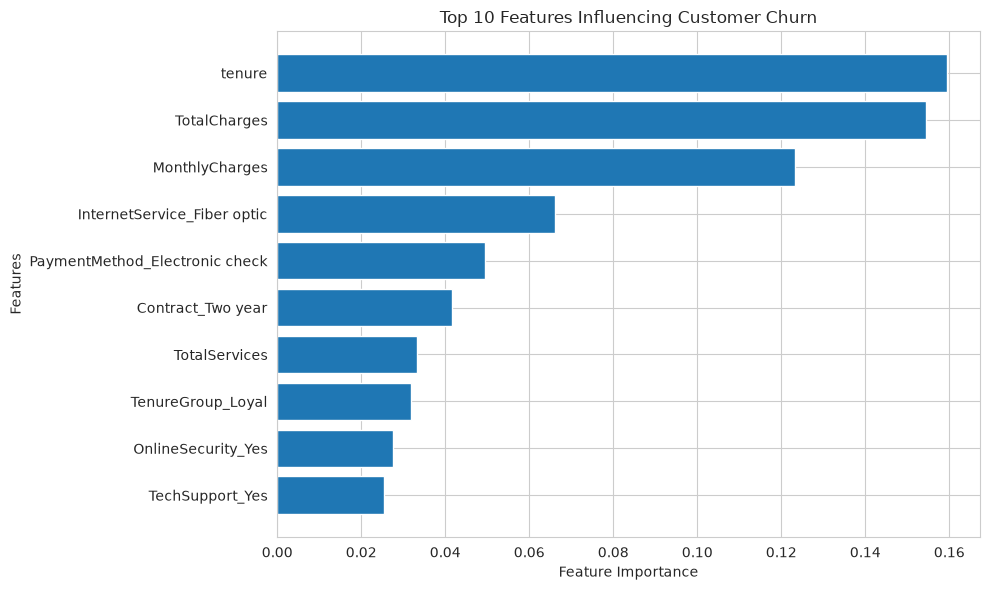

In [69]:

import matplotlib.pyplot as plt

top_features = rf_feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Features Influencing Customer Churn")

plt.tight_layout()
plt.show()

In [70]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    best_rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance.importances_mean,
    "Std": perm_importance.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Permutation Important Features:")
print(permutation_df.head(15).round(4))

Top 15 Permutation Important Features:
                               Feature  Importance     Std
3                               tenure      0.1023  0.0196
11         InternetService_Fiber optic      0.0943  0.0090
6                       MonthlyCharges      0.0523  0.0114
26                   Contract_Two year      0.0453  0.0130
7                         TotalCharges      0.0335  0.0173
25                   Contract_One year      0.0232  0.0081
28      PaymentMethod_Electronic check      0.0202  0.0095
33                   TenureGroup_Loyal      0.0179  0.0091
5                     PaperlessBilling      0.0139  0.0044
14                  OnlineSecurity_Yes      0.0133  0.0084
20                     TechSupport_Yes      0.0107  0.0042
10                   MultipleLines_Yes      0.0099  0.0066
19     TechSupport_No internet service      0.0083  0.0050
2                           Dependents      0.0075  0.0055
13  OnlineSecurity_No internet service      0.0073  0.0044


In [71]:
import joblib
import os

# Create model directory
os.makedirs("../models", exist_ok=True)

# Save Logistic Regression pipeline
joblib.dump(
    lr_pipeline,
    "../models/logistic_regression_pipeline.pkl"
)

# Save tuned Random Forest
joblib.dump(
    best_rf_model,
    "../models/tuned_random_forest.pkl"
)

# Save selected thresholds
model_thresholds = {
    "logistic_regression": 0.35,
    "random_forest": 0.30
}

joblib.dump(
    model_thresholds,
    "../models/model_thresholds.pkl"
)

print("Models saved successfully!")

Models saved successfully!
